In this project, I use Python libraries such as Requests and BeautifulSoup to collect book details from the Books to Scrape website. The extracted information can include book titles, prices, ratings, and availability. The collected data can then be organized into a Pandas DataFrame for analysis.

In [137]:
!pip -q install requests beautifulsoup4 pandas matplotlib seaborn

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin
5
print("All libraries imported successfully!")

All libraries imported successfully!


In [139]:
base_url = "https://books.toscrape.com/"
first_response = requests.get(base_url, timeout=20)

print("Status Code:", first_response.status_code)

if first_response.status_code != 200:
    raise Exception("Website could not be accessed.")

print("Website connected successfully!")

Status Code: 200
Website connected successfully!


In [140]:
soup = BeautifulSoup(first_response.text, "html.parser")

books = soup.select("article.product_pod")

print("Books found on first page:", len(books))

for book in books[:5]:
    title = book.select_one("h3 a")["title"]
    price = book.select_one(".price_color").get_text(strip=True)
    availability = book.select_one(".availability").get_text(strip=True)

    print("Title:", title)
    print("Price:", price)
    print("Availability:", availability)
    print("-" * 40)

Books found on first page: 20
Title: A Light in the Attic
Price: Â£51.77
Availability: In stock
----------------------------------------
Title: Tipping the Velvet
Price: Â£53.74
Availability: In stock
----------------------------------------
Title: Soumission
Price: Â£50.10
Availability: In stock
----------------------------------------
Title: Sharp Objects
Price: Â£47.82
Availability: In stock
----------------------------------------
Title: Sapiens: A Brief History of Humankind
Price: Â£54.23
Availability: In stock
----------------------------------------


In [141]:
all_books = []

base_url = "https://books.toscrape.com/"
total_pages = 50

for page in range(1, total_pages + 1):

    if page == 1:
        page_url = base_url
    else:
        page_url = f"{base_url}catalogue/page-{page}.html"

    response = requests.get(page_url, timeout=20)

    if response.status_code != 200:
        print(f"Skipping page {page}: HTTP {response.status_code}")
        continue

    soup = BeautifulSoup(response.text, "html.parser")
    book_cards = soup.select("article.product_pod")

    for book in book_cards:
        title = book.select_one("h3 a")["title"]

        price = book.select_one(
            ".price_color"
        ).get_text(strip=True)

        availability = book.select_one(
            ".availability"
        ).get_text(strip=True)

        rating_element = book.select_one("p.star-rating")
        rating = (
            rating_element.get("class")[1]
            if rating_element else "Unknown"
        )

        relative_url = book.select_one("h3 a")["href"]
        book_url = urljoin(page_url, relative_url)

        all_books.append({
            "Title": title,
            "Price": price,
            "Availability": availability,
            "Rating": rating,
            "Book URL": book_url
        })

    print(
        f"Page {page}: {len(book_cards)} books collected"
    )

    time.sleep(0.2)

df = pd.DataFrame(all_books)

print("\nScraping completed!")
print("Total books collected:", len(df))

display(df.head(10))

Page 1: 20 books collected
Page 2: 20 books collected
Page 3: 20 books collected
Page 4: 20 books collected
Page 5: 20 books collected
Page 6: 20 books collected
Page 7: 20 books collected
Page 8: 20 books collected
Page 9: 20 books collected
Page 10: 20 books collected
Page 11: 20 books collected
Page 12: 20 books collected
Page 13: 20 books collected
Page 14: 20 books collected
Page 15: 20 books collected
Page 16: 20 books collected
Page 17: 20 books collected
Page 18: 20 books collected
Page 19: 20 books collected
Page 20: 20 books collected
Page 21: 20 books collected
Page 22: 20 books collected
Page 23: 20 books collected
Page 24: 20 books collected
Page 25: 20 books collected
Page 26: 20 books collected
Page 27: 20 books collected
Page 28: 20 books collected
Page 29: 20 books collected
Page 30: 20 books collected
Page 31: 20 books collected
Page 32: 20 books collected
Page 33: 20 books collected
Page 34: 20 books collected
Page 35: 20 books collected
Page 36: 20 books collected
P

,Title,Price,Availability,Rating,Book URL
0,A Light in the Attic,Â£51.77,In stock,Three,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,In stock,One,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,In stock,One,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,In stock,Four,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock,Five,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,Â£22.65,In stock,One,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,In stock,Four,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,In stock,Three,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,In stock,Four,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,Â£52.15,In stock,One,https://books.toscrape.com/catalogue/the-black...


In [142]:
# Remove duplicate book URLs, if any
df = df.drop_duplicates(subset=["Book URL"]).copy()

# Clean text columns
for column in ["Title", "Availability", "Rating"]:
    df[column] = df[column].astype("string").str.strip()

# Convert prices from text to numeric values
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("£", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Dataset shape: (1000, 5)

Missing values:
Title              0
Price           1000
Availability       0
Rating             0
Book URL           0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   string 
 1   Price         0 non-null      float64
 2   Availability  1000 non-null   string 
 3   Rating        1000 non-null   string 
 4   Book URL      1000 non-null   object 
dtypes: float64(1), object(1), string(3)
memory usage: 39.2+ KB


In [143]:
csv_filename = "CodeAlpha_WebScraping.csv"

df.to_csv(csv_filename, index=False)

print("Dataset saved as:", csv_filename)
print("Total records saved:", len(df))

Dataset saved as: CodeAlpha_WebScraping.csv
Total records saved: 1000


In [144]:
from google.colab import files

files.download("CodeAlpha_WebScraping.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [145]:
print("WEB SCRAPING DATA ANALYSIS")
print("=" * 40)

print("\nTotal books:", len(df))

print("\nBooks by rating:")
print(df["Rating"].value_counts())

print("\nAvailability distribution:")
print(df["Availability"].value_counts())

print("\nPrice statistics:")
print(df["Price"].describe())

print("\nFive least expensive books:")
display(
    df.nsmallest(5, "Price")[["Title", "Price", "Rating"]]
)

print("\nFive most expensive books:")
display(
    df.nlargest(5, "Price")[["Title", "Price", "Rating"]]
)

WEB SCRAPING DATA ANALYSIS

Total books: 1000

Books by rating:
Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: Int64

Availability distribution:
Availability
In stock    1000
Name: count, dtype: Int64

Price statistics:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Price, dtype: float64

Five least expensive books:


,Title,Price,Rating
0,A Light in the Attic,NaN,Three
1,Tipping the Velvet,NaN,One
2,Soumission,NaN,One
3,Sharp Objects,NaN,Four
4,Sapiens: A Brief History of Humankind,NaN,Five



Five most expensive books:


,Title,Price,Rating
0,A Light in the Attic,NaN,Three
1,Tipping the Velvet,NaN,One
2,Soumission,NaN,One
3,Sharp Objects,NaN,Four
4,Sapiens: A Brief History of Humankind,NaN,Five


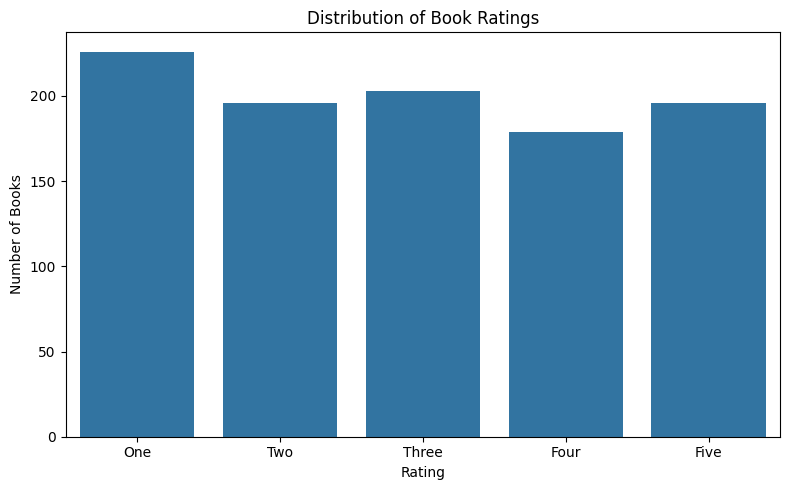

In [146]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Rating",
    order=["One", "Two", "Three", "Four", "Five"]
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

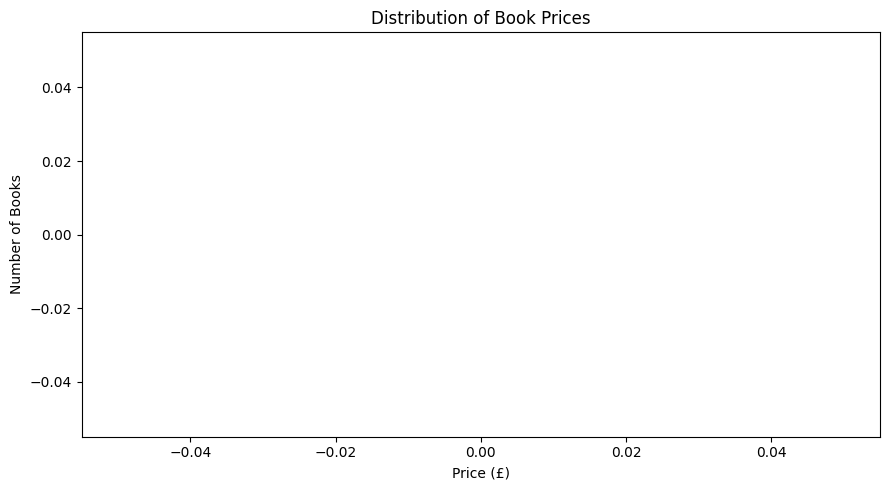

In [147]:
plt.figure(figsize=(9, 5))

sns.histplot(df["Price"].dropna(), bins=20, kde=True)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

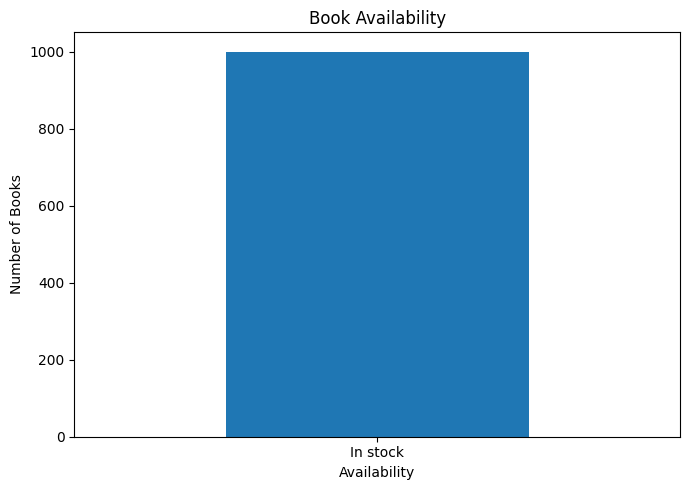

In [148]:
availability_counts = df["Availability"].value_counts()

plt.figure(figsize=(7, 5))

availability_counts.plot(kind="bar")

plt.title("Book Availability")
plt.xlabel("Availability")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

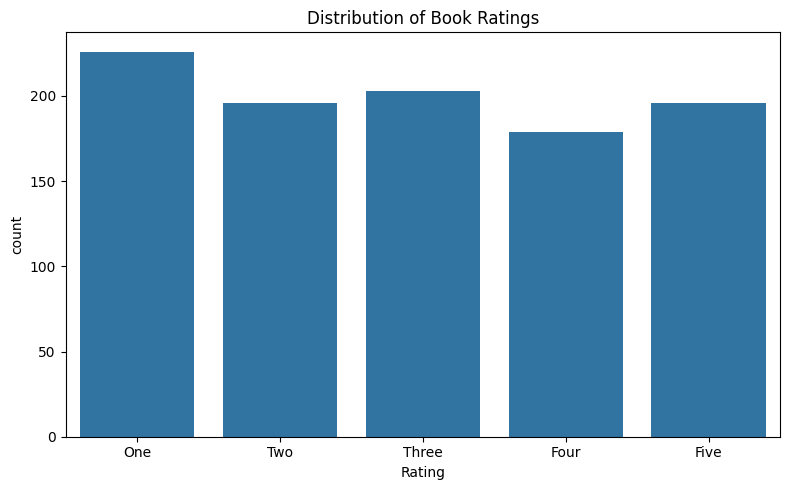

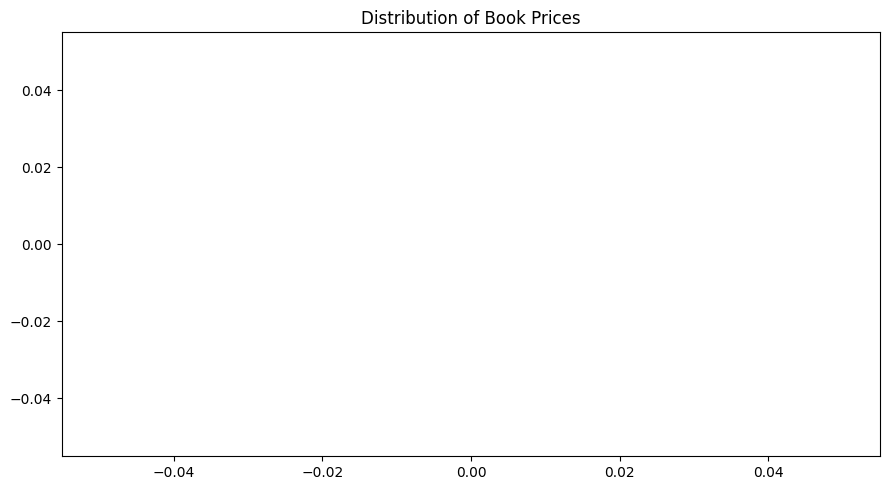

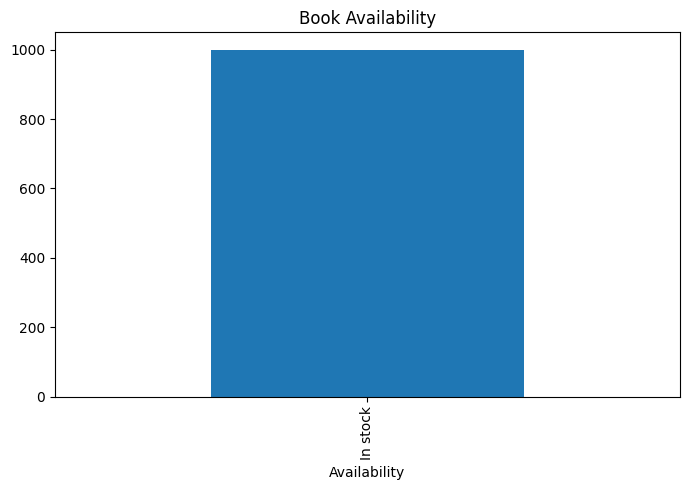

Charts saved in the visualizations folder!


In [149]:
import os

os.makedirs("visualizations", exist_ok=True)

# Chart 1
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Rating",
    order=["One", "Two", "Three", "Four", "Five"]
)
plt.title("Distribution of Book Ratings")
plt.tight_layout()
plt.savefig("visualizations/book_ratings.png", dpi=150)
plt.show()
plt.close()

# Chart 2
plt.figure(figsize=(9, 5))
sns.histplot(df["Price"].dropna(), bins=20, kde=True)
plt.title("Distribution of Book Prices")
plt.tight_layout()
plt.savefig("visualizations/book_prices.png", dpi=150)
plt.show()
plt.close()

# Chart 3
plt.figure(figsize=(7, 5))
availability_counts.plot(kind="bar")
plt.title("Book Availability")
plt.tight_layout()
plt.savefig("visualizations/book_availability.png", dpi=150)
plt.show()
plt.close()

print("Charts saved in the visualizations folder!")

# Conclusion

The Web Scraping project uses Python to collect book information from the Books to Scrape practice website.

The project extracts book titles, prices, ratings, availability, and product page URLs using the Requests and BeautifulSoup libraries.

The collected information is organized into a structured Pandas DataFrame and exported to a CSV file. Data validation and exploratory analysis are used to examine the collected records, while Matplotlib and Seaborn create visualizations of book ratings, prices, and availability.

This project demonstrates the basic web-scraping workflow, from retrieving webpage content and parsing HTML to storing, analyzing, and visualizing structured data.

**Tools used:** Python, Requests, BeautifulSoup, Pandas, Matplotlib, Seaborn, and Google Colab.